# 第 39 章：市场风险资本与模型风险

本章例题、表格与图形中的每一个数字，按顺序重新计算（第 39.16 节境内部分的数字由 `tools/verify/ch39-market-risk-capital.py` 核对，此处不重复）。使用 **NumPy、SciPy 与 Matplotlib**，但有一处例外，因为那里要求精确复现：例 39.5 中模拟的 Kolmogorov–Smirnov 一栏，其正态随机数由 Python 自带的 `random.Random(39).random()` 经 Box–Muller 公式生成，因为这个生成器在任何机器、任何版本上都给出同样的数，而 `random.gauss` 与 NumPy 的生成器并不作此保证。

每个数字都与本章所印的数值并列，并标出 `ok` 或 `DIFFERS`；最后一个单元格列出所有不符之处。

| 节 | 复现的内容 | 例 / 图 |
|---|---|---|
| 1 | 账簿边界上的资本差额；一个利率风险组的三种相关性情景 | 第 39.2 节，39.1，图 39.1 |
| 2 | 曲率即偏离 delta 直线的缺口；delta 对冲的期权空头 | 39.2，图 39.2 |
| 3 | 流动性期间表作为资本乘数 | 39.3 |
| 4 | 一个无法建模因子的两项惩罚 | 39.4 |
| 5 | 损益归因检验：Spearman 相关系数与 Kolmogorov–Smirnov 统计量 | 39.5，图 39.3 |
| 6 | 资本总额的构成；回测乘数 | 39.6 |
| 7 | 输出下限与交易台失去批准的代价 | 39.7 |
| 8 | 内部评级法风险权重与 72.5% 的标准法权重 | 39.8，图 39.5 |
| 9 | 审慎估值：1 亿美元账簿上的扣除 | 39.9 |

图 39.4 是流程图，不含数字。

下面的辅助函数在全篇通用。`show` 把计算结果与本章所印的数值并列，容差与所印的舍入位数一致。

In [1]:
import random
from math import asin, cos, exp, log, pi, sin, sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

N, phi, Ninv = norm.cdf, norm.pdf, norm.ppf
BAD = []

# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one, told apart by dash pattern as well as color.
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})


def show(label, got, printed, tol=5e-4):
    """A figure beside the chapter's. `tol` is absolute and matches the printed rounding."""
    ok = abs(got - printed) <= tol
    if not ok:
        BAD.append(label)
    print("%-52s %14.4f   book %13.4f   %s" % (label, got, printed, "ok" if ok else "DIFFERS"))

## 1. 账簿边界，以及三种相关性情景：第 39.2 节，例 39.1

第 39.2 节中 5 亿美元的公司债，放在交易账簿里资本占用 3%，放在银行账簿里则是 8%，分类本身就值 5 个百分点的资本。

例 39.1 取一个币种的利率曲线上 2 年、5 年与 10 年三个点。银行为每个点报告净敏感度 $s_k$，即仅该点利率上升一个基点时，该曲线上全部头寸的损失。监管者给出风险权重 $RW_k$（130、110 与 110 个基点）与相关性

$$\rho_{kl} = \max\bigl(e^{-0.03\,|T_k - T_l|/\min(T_k, T_l)},\; 0.40\bigr).$$

加权敏感度为 $WS_k = s_k \times RW_k$，风险组资本为 $K_b = \sqrt{\max\bigl(0,\ \sum_k WS_k^2 + \sum_{k \ne l} \rho_{kl} WS_k WS_l\bigr)}$，共计算三次：分别用规定的相关性、$\min(1.25\rho, 1)$ 与 $\max(2\rho - 1,\ 0.75\rho)$。资本取三者中的最大值。

In [2]:
show("Section 39.2: $500m at 8% against 3% ($m)", 500 * (0.08 - 0.03), 25, 1e-9)

TENORS = np.array([2, 5, 10])                  # years
RW = np.array([130, 110, 110])                 # risk weights, basis points


def corr(a, b):
    return max(exp(-0.03 * abs(a - b) / min(a, b)), 0.40)


RHO = np.array([[corr(a, b) for b in TENORS] for a in TENORS])
LOW = np.maximum(2 * RHO - 1, 0.75 * RHO)
HIGH = np.minimum(1.25 * RHO, 1.0)
for (i, j), med, low in (((0, 1), 0.9560, 0.9120), ((1, 2), 0.9704, 0.9409), ((0, 2), 0.8869, 0.7738)):
    show("rho %dy-%dy, prescribed" % (TENORS[i], TENORS[j]), RHO[i, j], med, 5e-5)
    show("  low scenario (2 rho - 1 governs)", LOW[i, j], low, 5e-5)
show("high scenario: every correlation capped at one", HIGH.min(), 1.0, 0)
show("10y-13y, the same three-year gap further out", corr(10, 13), 0.991, 5e-4)

Section 39.2: $500m at 8% against 3% ($m)                   25.0000   book       25.0000   ok
rho 2y-5y, prescribed                                        0.9560   book        0.9560   ok
  low scenario (2 rho - 1 governs)                           0.9120   book        0.9120   ok
rho 5y-10y, prescribed                                       0.9704   book        0.9704   ok
  low scenario (2 rho - 1 governs)                           0.9409   book        0.9409   ok
rho 2y-10y, prescribed                                       0.8869   book        0.8869   ok
  low scenario (2 rho - 1 governs)                           0.7738   book        0.7738   ok
high scenario: every correlation capped at one               1.0000   book        1.0000   ok
10y-13y, the same three-year gap further out                 0.9910   book        0.9910   ok


In [3]:
def bucket(ws, rho):
    return sqrt(max(0.0, ws @ rho @ ws))


BOOKS = {"directional": np.array([2000, 3000, 4000]),        # $ per basis point
         "butterfly": np.array([2200, -4600, 2000])}
PRINTED = {"directional": (988376, 1009403, 1030000, 2.0), "butterfly": (100854, 71315, 0, 41.4)}
CHARGES = {}
for name, s in BOOKS.items():
    ws = s * RW
    k = [bucket(ws, r) for r in (LOW, RHO, HIGH)]
    CHARGES[name] = k
    print("%s: weighted sensitivities %s, sum %d" % (name, ws.tolist(), ws.sum()))
    for lab, got, printed in zip(("low", "medium", "high"), k, PRINTED[name]):
        show("  %s, %s ($)" % (name, lab), got, printed, 0.5)
    show("  worst over medium (%)", 100 * (max(k) / k[1] - 1), PRINTED[name][3], 0.05)

ws_d = BOOKS["directional"] * RW / 1000
show("directional K_b^2 at medium ($000 squared)", ws_d @ RHO @ ws_d, 1018894, 0.5)
show("butterfly: parallel one-basis-point move ($)", abs(BOOKS["butterfly"].sum()), 400, 0)

directional: weighted sensitivities [260000, 330000, 440000], sum 1030000
  directional, low ($)                                  988376.3926   book   988376.0000   ok
  directional, medium ($)                              1009402.7674   book  1009403.0000   ok
  directional, high ($)                                1030000.0000   book  1030000.0000   ok
  worst over medium (%)                                      2.0405   book        2.0000   ok
butterfly: weighted sensitivities [286000, -506000, 220000], sum 0
  butterfly, low ($)                                    100854.4595   book   100854.0000   ok
  butterfly, medium ($)                                  71314.8723   book    71315.0000   ok
  butterfly, high ($)                                        0.0000   book        0.0000   ok
  worst over medium (%)                                     41.4214   book       41.4000   ok
directional K_b^2 at medium ($000 squared)             1018893.9467   book  1018894.0000   ok
butterfly: pa

**图 39.1。** 三种情景下的风险组资本。方向性账簿在曲线同向变动时资本最高；蝶式的各端相互抵消，在曲线不同向变动时资本最高。

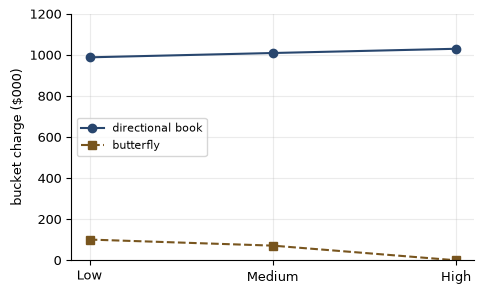

In [4]:
fig, ax = plt.subplots(figsize=(5.2, 3.2))
x = [1, 2, 3]
ax.plot(x, np.array(CHARGES["directional"]) / 1e3, color=BLUE, marker="o", label="directional book")
ax.plot(x, np.array(CHARGES["butterfly"]) / 1e3, color=AMBER, ls="--", marker="s", label="butterfly")
ax.set_xticks(x, ["Low", "Medium", "High"])
ax.set_ylim(0, 1200)
ax.set_ylabel("bucket charge ($000)")
ax.legend(loc="center left", fontsize=8)
plt.show()

## 2. 曲率，以及 delta 对冲的期权空头：例 39.2

一份名义金额 1,000 万美元、以一只新兴市场大盘股为标的的平值看涨期权，期限 6 个月，波动率 25%，利率为零。曲率计提在 ±55% 的冲击下重估头寸，对重估结果比 delta 预测多出的损失计提资本，下限为零。vega 按波动率的*相对*变动报告，其风险权重为 $\min(55\% \times \sqrt{\mathrm{LH}/10},\ 100\%)$，大盘股波动率的流动性期间为 20 天。

对看涨期权多头，两个缺口都对持有人有利，因此曲率计提为零；例 39.2 的交易台卖出该期权并作 delta 对冲，同样的缺口就成了损失。

In [5]:
NOTIONAL, SIG, T, SHOCK = 10e6, 0.25, 0.5, 0.55


def call(x, sig=SIG, T=T):
    """At-the-money call per unit of notional, with the stock at x times today's price; r = 0."""
    if x <= 0:
        return 0.0
    d1 = (log(x) + sig * sig / 2 * T) / (sig * sqrt(T))
    return x * N(d1) - N(d1 - sig * sqrt(T))


d1 = SIG * sqrt(T) / 2
V0 = NOTIONAL * call(1.0)
delta = N(d1)
show("d1 = 0.25 sqrt(0.5) / 2", d1, 0.0884, 5e-5)
show("option value ($)", V0, 704000, 500)
show("delta", delta, 0.5352, 5e-5)
show("dollar delta ($m)", NOTIONAL * delta / 1e6, 5.352, 5e-4)

v_up, v_dn = NOTIONAL * call(1 + SHOCK), NOTIONAL * call(1 - SHOCK)
pred_up, pred_dn = V0 + NOTIONAL * delta * SHOCK, V0 - NOTIONAL * delta * SHOCK
show("value after +55% ($m)", v_up / 1e6, 5.505, 5e-4)
show("delta prediction, +55% ($m)", pred_up / 1e6, 3.648, 5e-4)
show("delta prediction, -55% ($m)", pred_dn / 1e6, -2.239, 5e-4)
gap_up, gap_dn = v_up - pred_up, v_dn - pred_dn
show("long call: revaluation beats delta, up ($m)", gap_up / 1e6, 1.86, 0.005)
show("long call: revaluation beats delta, down ($m)", gap_dn / 1e6, 2.24, 0.005)
show("long call curvature charge, floored ($)", max(0.0, -min(gap_up, gap_dn)), 0.0, 0.5)
curvature = max(0.0, max(gap_up, gap_dn))          # the short call loses both gaps
show("short call curvature charge ($)", curvature, 2239369, 0.5)

d1 = 0.25 sqrt(0.5) / 2                                      0.0884   book        0.0884   ok
option value ($)                                        704319.7772   book   704000.0000   ok
delta                                                        0.5352   book        0.5352   ok
dollar delta ($m)                                            5.3522   book        5.3520   ok
value after +55% ($m)                                        5.5047   book        5.5050   ok
delta prediction, +55% ($m)                                  3.6480   book        3.6480   ok
delta prediction, -55% ($m)                                 -2.2394   book       -2.2390   ok
long call: revaluation beats delta, up ($m)                  1.8567   book        1.8600   ok
long call: revaluation beats delta, down ($m)                2.2394   book        2.2400   ok
long call curvature charge, floored ($)                      0.0000   book        0.0000   ok
short call curvature charge ($)                        22393

In [6]:
vega_point = NOTIONAL * sqrt(T) * phi(d1) / 100       # per volatility point
show("vega per volatility point ($)", vega_point, 28099.50, 0.005)
vega_reported = vega_point * 100 * SIG                  # against a relative change: x 25
show("reported vega sensitivity ($)", vega_reported, 702488, 0.5)
rw_vega = min(0.55 * sqrt(20 / 10), 1.0)
show("vega risk weight, 20-day horizon (%)", 100 * rw_vega, 77.8, 0.05)
vega_charge = rw_vega * vega_reported
show("vega charge ($)", vega_charge, 546407, 0.5)
total = vega_charge + curvature
show("total charge ($)", total, 2785776, 1.0)
show("  as % of notional", 100 * total / NOTIONAL, 27.9, 0.05)
show("  curvature share (%)", 100 * curvature / total, 80, 0.5)
show("residual risk add-on, $50m exotic and $200m other ($m)", 0.01 * 50 + 0.001 * 200, 0.7, 1e-9)

vega per volatility point ($)                            28099.5008   book    28099.5000   ok
reported vega sensitivity ($)                           702487.5210   book   702488.0000   ok
vega risk weight, 20-day horizon (%)                        77.7817   book       77.8000   ok
vega charge ($)                                         546407.0588   book   546407.0000   ok
total charge ($)                                       2785775.9748   book  2785776.0000   ok
  as % of notional                                          27.8578   book       27.9000   ok
  curvature share (%)                                       80.3858   book       80.0000   ok
residual risk add-on, $50m exotic and $200m other ($m)         0.7000   book        0.7000   ok


**图 39.2。** 看涨期权多头的价值与其 delta 直线，以及两个曲率冲击处的缺口。

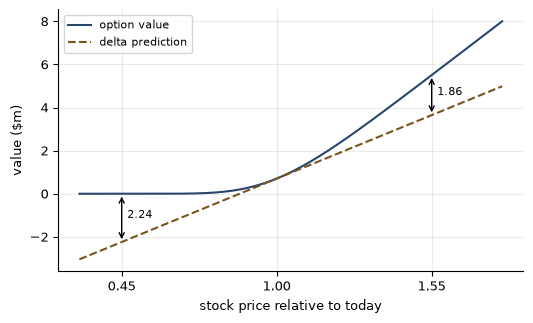

In [7]:
xs = np.linspace(0.3, 1.8, 151)
fig, ax = plt.subplots(figsize=(6.0, 3.4))
ax.plot(xs, [10 * call(x) for x in xs], color=BLUE, label="option value")
ax.plot(xs, V0 / 1e6 + NOTIONAL * delta / 1e6 * (xs - 1), color=AMBER, ls="--", label="delta prediction")
for x0, lo, hi in ((1 + SHOCK, pred_up, v_up), (1 - SHOCK, pred_dn, v_dn)):
    ax.annotate("", xy=(x0, hi / 1e6), xytext=(x0, lo / 1e6), arrowprops=dict(arrowstyle="<->", lw=1))
    ax.text(x0 + 0.02, (lo + hi) / 2e6, "%.2f" % ((hi - lo) / 1e6), fontsize=8)
ax.set_xticks([0.45, 1, 1.55])
ax.set_xlabel("stock price relative to today")
ax.set_ylabel("value ($m)")
ax.legend(loc="upper left", fontsize=8)
plt.show()

## 3. 流动性期间表本身就是一个资本乘数：例 39.3

框架为每个风险因子规定 10、20、40、60 或 120 天的流动性期间。$\mathrm{ES}_1$ 冲击所有因子，$\mathrm{ES}_j$ 只冲击流动性期间至少为 $\mathrm{LH}_j$ 的因子。取 $\mathrm{LH}_0 = 0$，

$$\mathrm{ES} = \sqrt{\sum_j \Bigl(\mathrm{ES}_j \sqrt{(\mathrm{LH}_j - \mathrm{LH}_{j-1})/10}\Bigr)^2 }.$$

该交易台的各分项 ES 依次为 100、90、70、45 与 20。

In [8]:
LH = np.array([10, 20, 40, 60, 120])
weights = np.sqrt(np.diff(np.concatenate(([0], LH))) / 10)
weights[0] = 1.0                                   # the first term carries ES_1 at weight one
for j, printed in enumerate((1.0000, 1.0000, 1.4142, 1.4142, 2.4495)):
    show("weight, %d-day horizon" % LH[j], weights[j], printed, 5e-5)
show("total scaling of a 120-day factor", sqrt((weights ** 2).sum()), 3.46, 0.005)

ES = np.array([100, 90, 70, 45, 20])
es_total = sqrt(((ES * weights) ** 2).sum())
show("aggregate ES", es_total, 185.34, 0.005)
show("multiple of the flat ten-day figure", es_total / ES[0], 1.85, 0.005)

weight, 10-day horizon                                       1.0000   book        1.0000   ok
weight, 20-day horizon                                       1.0000   book        1.0000   ok
weight, 40-day horizon                                       1.4142   book        1.4142   ok
weight, 60-day horizon                                       1.4142   book        1.4142   ok
weight, 120-day horizon                                      2.4495   book        2.4495   ok
total scaling of a 120-day factor                            3.4641   book        3.4600   ok
aggregate ES                                               185.3375   book      185.3400   ok
multiple of the flat ten-day figure                          1.8534   book        1.8500   ok


## 4. 一个不流动因子，两项惩罚：例 39.4

某交易台的可建模风险给出的 ES 为 80，一个不流动因子为 30。若该因子可以建模，两者将以相关性 $\rho$ 分散化；作为无法建模的因子，它按压力情景计提资本（这里假定为其 ES 的 1.6 倍），而且相加时不分散化。两项惩罚分别是失去的分散化与压力校准。

本节还说明，非特质性的压力情景以参数 0.6 合并，相当于任意两者之间的相关性为 $0.6^2 = 0.36$。

In [9]:
A, B, STRESS = 80.0, 30.0, 1.6
nmrf = A + STRESS * B
show("NMRF treatment: 80 + 1.6 x 30", nmrf, 128.0, 1e-9)
for rho, div_p, pct_p, lost_p in ((0.25, 92.2, 38.8, 17.8), (0.50, 98.5, 30.0, 11.5)):
    div = sqrt(A * A + B * B + 2 * rho * A * B)
    show("rho %.2f: fully modellable, diversified" % rho, div, div_p, 0.05)
    show("  increase (%)", 100 * (nmrf / div - 1), pct_p, 0.05)
    show("  lost diversification", A + B - div, lost_p, 0.05)
show("stress calibration, 1.6 x 30 - 30", STRESS * B - B, 18.0, 1e-9)
show("total difference at 0.25", nmrf - sqrt(A * A + B * B + 2 * 0.25 * A * B), 35.8, 0.05)
show("pairwise correlation implied by the 0.6 parameter", 0.6 ** 2, 0.36, 1e-12)

NMRF treatment: 80 + 1.6 x 30                              128.0000   book      128.0000   ok
rho 0.25: fully modellable, diversified                     92.1954   book       92.2000   ok
  increase (%)                                              38.8355   book       38.8000   ok
  lost diversification                                      17.8046   book       17.8000   ok
rho 0.50: fully modellable, diversified                     98.4886   book       98.5000   ok
  increase (%)                                              29.9643   book       30.0000   ok
  lost diversification                                      11.5114   book       11.5000   ok
stress calibration, 1.6 x 30 - 30                           18.0000   book       18.0000   ok
total difference at 0.25                                    35.8046   book       35.8000   ok
pairwise correlation implied by the 0.6 parameter            0.3600   book        0.3600   ok


## 5. 三分之一的损益无法解释也无妨：例 39.5

风险理论损益为 $\sqrt{1-f}\,Z_1$，假设损益再加上 $\sqrt{f}\,Z_2$，因此假设损益方差中有比例 $f$ 无法解释，Pearson 相关系数为 $\sqrt{1-f}$。对二元正态分布，Spearman 秩相关系数有闭式解：

$$\rho_S = \frac{6}{\pi}\arcsin\frac{\sqrt{1-f}}{2}.$$

秩相关 $\rho_S$ 高于 0.80 且 KS 低于 0.09 时，交易台处于绿区，$\rho_S$ 低于 0.70 或 KS 高于 0.12 时处于红区。Kolmogorov–Smirnov 一栏由模拟得到：2,000 个 250 天的样本，每个样本比较两组序列的经验分布。

In [10]:
def rho_s(f):
    return 6 / pi * asin(sqrt(1 - f) / 2)


def f_at(rs):
    """The unexplained share at which the Spearman correlation equals rs."""
    return 1 - (2 * sin(rs * pi / 6)) ** 2


for f, rho_p, sp in ((0.05, 0.9747, 0.9722), (0.20, 0.8944, 0.8855), (0.30, 0.8367, 0.8243),
                     (0.40, 0.7746, 0.7595), (0.50, 0.7071, 0.6902)):
    show("f = %.0f%%: Pearson" % (100 * f), sqrt(1 - f), rho_p, 5e-5)
    show("  Spearman", rho_s(f), sp, 5e-5)
F_AMBER, F_RED = f_at(0.80), f_at(0.70)
show("f where rho_S = 0.80, amber begins (%)", 100 * F_AMBER, 33.8, 0.05)
show("f where rho_S = 0.70, red begins (%)", 100 * F_RED, 48.6, 0.05)

f = 5%: Pearson                                              0.9747   book        0.9747   ok
  Spearman                                                   0.9722   book        0.9722   ok
f = 20%: Pearson                                             0.8944   book        0.8944   ok
  Spearman                                                   0.8855   book        0.8855   ok
f = 30%: Pearson                                             0.8367   book        0.8367   ok
  Spearman                                                   0.8243   book        0.8243   ok
f = 40%: Pearson                                             0.7746   book        0.7746   ok
  Spearman                                                   0.7595   book        0.7595   ok
f = 50%: Pearson                                             0.7071   book        0.7071   ok
  Spearman                                                   0.6902   book        0.6902   ok
f where rho_S = 0.80, amber begins (%)                      

模拟中的每个正态随机数都由 `random.Random(39)` 经 Box–Muller 公式生成，因此这一栏可以精确复现。运行需要几秒钟。

In [11]:
def ks_statistic(a, b):
    """Two-sample Kolmogorov-Smirnov: the largest gap between the two empirical distribution functions."""
    grid = np.concatenate((a, b))
    fa = np.searchsorted(np.sort(a), grid, side="right") / len(a)
    fb = np.searchsorted(np.sort(b), grid, side="right") / len(b)
    return np.abs(fa - fb).max()


def ks_column(fs, reps=2000, days=250, seed=39):
    rng = random.Random(seed)

    def gauss():
        u1, u2 = 1.0 - rng.random(), rng.random()
        return sqrt(-2 * log(u1)) * cos(2 * pi * u2)

    total = {f: 0.0 for f in fs}
    above = {f: 0 for f in fs}
    for _ in range(reps):
        z1 = np.array([gauss() for _ in range(days)])
        z2 = np.array([gauss() for _ in range(days)])
        for f in fs:
            risk_theoretical = sqrt(1 - f) * z1
            k = ks_statistic(risk_theoretical, risk_theoretical + sqrt(f) * z2)
            total[f] += k
            above[f] += k > 0.09
    return {f: (total[f] / reps, above[f] / reps) for f in fs}


KS = ks_column([0.05, 0.20, 0.30, F_AMBER, 0.35, 0.40, F_RED, 0.50])
for f, printed in ((0.05, 0.043), (0.20, 0.065), (0.30, 0.081), (F_AMBER, 0.088), (0.40, 0.099),
                   (F_RED, 0.117), (0.50, 0.120)):
    show("mean KS at f = %.1f%%" % (100 * f), KS[f][0], printed, 5e-4)
show("mean KS reaches 0.09 near 35%", KS[0.35][0], 0.09, 0.0015)
show("P(KS > 0.09) at 30%, about one in four", KS[0.30][1], 0.25, 0.02)

mean KS at f = 5.0%                                          0.0430   book        0.0430   ok
mean KS at f = 20.0%                                         0.0655   book        0.0650   ok
mean KS at f = 30.0%                                         0.0810   book        0.0810   ok
mean KS at f = 33.8%                                         0.0876   book        0.0880   ok
mean KS at f = 40.0%                                         0.0990   book        0.0990   ok
mean KS at f = 48.6%                                         0.1168   book        0.1170   ok
mean KS at f = 50.0%                                         0.1199   book        0.1200   ok
mean KS reaches 0.09 near 35%                                0.0897   book        0.0900   ok
P(KS > 0.09) at 30%, about one in four                       0.2595   book        0.2500   ok


**图 39.3。** Spearman 相关系数与无法解释的方差比例，以及绿区与红区的阈值。

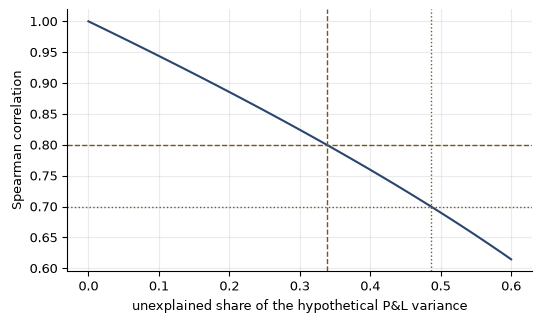

In [12]:
fs = np.linspace(0, 0.6, 121)
fig, ax = plt.subplots(figsize=(6.0, 3.4))
ax.plot(fs, [rho_s(f) for f in fs], color=BLUE)
for level, f0, ls in ((0.80, F_AMBER, "--"), (0.70, F_RED, ":")):
    ax.axhline(level, color=AMBER, ls=ls, lw=1)
    ax.axvline(f0, color=AMBER, ls=ls, lw=1)
ax.set_xlabel("unexplained share of the hypothetical P&L variance")
ax.set_ylabel("Spearman correlation")
plt.show()

## 6. 资本从哪里来：例 39.6

建模部分为 $\max(\mathrm{IMCC}_{t-1} + \mathrm{SES}_{t-1},\ m_c\,\overline{\mathrm{IMCC}} + \overline{\mathrm{SES}})$，横线表示 60 天平均值，$m_c$ 由全行的回测突破次数决定。再加上获批交易台的违约风险资本与其余交易台的标准法资本，便得到总额。

In [13]:
IMCC_1, IMCC_BAR, SES_1, SES_BAR = 420, 380, 95, 88


def modeled(mc):
    return max(IMCC_1 + SES_1, mc * IMCC_BAR + SES_BAR)


show("yesterday's term, 420 + 95", IMCC_1 + SES_1, 515, 0)
green = modeled(1.5)
show("modeled charge at m_c = 1.50 (green)", green, 658, 0)
for mc, printed, rise in ((1.7, 734, 11.6), (2.0, 848, 28.9)):
    show("modeled charge at m_c = %.2f" % mc, modeled(mc), printed, 1e-9)
    show("  increase over green (%)", 100 * (modeled(mc) / green - 1), rise, 0.05)

parts = {"modeled measure (ES and NMRF)": (658, 60.2), "default risk charge, approved desks": (140, 12.8),
         "desks on the standardized approach": (295, 27.0)}
grand = sum(v for v, _ in parts.values())
show("total", grand, 1093, 0)
for name, (v, share) in parts.items():
    show("  %s (%%)" % name, 100 * v / grand, share, 0.05)
show("  of which residual risk add-on (%)", 100 * 35 / grand, 3.2, 0.05)

yesterday's term, 420 + 95                                 515.0000   book      515.0000   ok
modeled charge at m_c = 1.50 (green)                       658.0000   book      658.0000   ok
modeled charge at m_c = 1.70                               734.0000   book      734.0000   ok
  increase over green (%)                                   11.5502   book       11.6000   ok
modeled charge at m_c = 2.00                               848.0000   book      848.0000   ok
  increase over green (%)                                   28.8754   book       28.9000   ok
total                                                     1093.0000   book     1093.0000   ok
  modeled measure (ES and NMRF) (%)                         60.2013   book       60.2000   ok
  default risk charge, approved desks (%)                   12.8088   book       12.8000   ok
  desks on the standardized approach (%)                    26.9899   book       27.0000   ok
  of which residual risk add-on (%)                         

## 7. 同一个交易台失败，三家银行，三种代价：例 39.7

每家银行的标准法风险加权资产，交易业务为 100，其他业务为 900，因此下限为 1,000 的 72.5%。其唯一的交易台按模型计为 60，按标准法计为 100。失去批准的代价取决于银行离下限已有多近。

In [14]:
FLOOR = 0.725 * (100 + 900)
show("output floor", FLOOR, 725, 0)
for bank, other, printed in (("A", 700, 40), ("B", 600, 0), ("C", 640, 15)):
    keep, lose = max(other + 60, FLOOR), max(other + 100, FLOOR)
    print("bank %s: modeled non-trading %d, held %.0f if the desk keeps approval, %.0f if it loses it"
          % (bank, other, keep, lose))
    show("  cost of failing", lose - keep, printed, 0)
show("Section 39.8: losing approval takes the desk of this example from 60 to 100 (%)", 100 * (100 / 60 - 1), 66.7, 0.05)

output floor                                               725.0000   book      725.0000   ok
bank A: modeled non-trading 700, held 760 if the desk keeps approval, 800 if it loses it
  cost of failing                                           40.0000   book       40.0000   ok
bank B: modeled non-trading 600, held 725 if the desk keeps approval, 725 if it loses it
  cost of failing                                            0.0000   book        0.0000   ok
bank C: modeled non-trading 640, held 725 if the desk keeps approval, 740 if it loses it
  cost of failing                                           15.0000   book       15.0000   ok
Section 39.8: losing approval takes the desk of this example from 60 to 100 (%)        66.6667   book       66.7000   ok


## 8. 下限在贷款账簿上从哪里起作用：例 39.8

违约损失率为 40%、期限为 2.5 年的公司贷款，内部评级法下每单位风险暴露的资本要求为

$$K = \mathrm{LGD}\Bigl[N\Bigl(\frac{N^{-1}(\mathrm{PD}) + \sqrt{\rho}\,N^{-1}(0.999)}{\sqrt{1-\rho}}\Bigr) - \mathrm{PD}\Bigr]
\frac{1 + (M - 2.5)\,b}{1 - 1.5\,b},$$

其中 $w = (1 - e^{-50\,\mathrm{PD}})/(1 - e^{-50})$，$\rho = 0.12\,w + 0.24\,(1 - w)$，$b = (0.11852 - 0.05478 \ln \mathrm{PD})^2$，违约概率下限为 0.05%，风险权重为 $12.5K$。违约概率取自表 24.2。

In [15]:
def irb(pd, lgd=0.40, M=2.5):
    pd = max(pd, 0.0005)
    w = (1 - exp(-50 * pd)) / (1 - exp(-50))
    rho = 0.12 * w + 0.24 * (1 - w)
    b = (0.11852 - 0.05478 * log(pd)) ** 2
    ma = (1 + (M - 2.5) * b) / (1 - 1.5 * b)
    wcdr = N((Ninv(pd) + sqrt(rho) * Ninv(0.999)) / sqrt(1 - rho))
    K = lgd * (wcdr - pd) * ma
    return dict(w=w, rho=rho, b=b, ma=ma, wcdr=wcdr, K=K, rw=12.5 * K)


BBB = irb(0.0028)
show("BBB: w", BBB["w"], 0.1306, 5e-5)
show("BBB: rho", BBB["rho"], 0.2243, 5e-5)
show("BBB: argument of N", (Ninv(0.0028) + sqrt(BBB["rho"]) * Ninv(0.999)) / sqrt(1 - BBB["rho"]), -1.4837, 5e-5)
show("BBB: worst-case default rate (%)", 100 * BBB["wcdr"], 6.895, 5e-4)
show("BBB: b", BBB["b"], 0.1941, 5e-5)
show("BBB: K (%)", 100 * BBB["K"], 3.73, 0.005)
show("BBB: risk weight 12.5K (%)", 100 * BBB["rw"], 46.7, 0.05)

RATINGS = (("A", 0.0005, 50, 0.35), ("BBB", 0.0028, 75, 0.62), ("BB", 0.0152, 100, 0.94),
           ("B", 0.0645, 150, 0.97), ("CCC", 0.3060, 150, 1.47))
PRINTED_RW = {"A": 17.5, "BBB": 46.7, "BB": 94.2, "B": 145.6, "CCC": 221.1}
print("%-5s %8s %8s %10s %9s %8s %8s" % ("grade", "PD %", "rho", "WCDR %", "IRB RW %", "SA %", "IRB/SA"))
for g, pd, sa, ratio in RATINGS:
    r = irb(pd)
    print("%-5s %8.2f %8.3f %10.2f %9.1f %8.0f %8.2f"
          % (g, 100 * pd, r["rho"], 100 * r["wcdr"], 100 * r["rw"], sa, r["rw"] / (sa / 100)))
    show("  %s: IRB risk weight (%%)" % g, 100 * r["rw"], PRINTED_RW[g], 0.05)
    show("  %s: ratio to standardized" % g, r["rw"] / (sa / 100), ratio, 0.005)

BBB: w                                                       0.1306   book        0.1306   ok
BBB: rho                                                     0.2243   book        0.2243   ok
BBB: argument of N                                          -1.4837   book       -1.4837   ok
BBB: worst-case default rate (%)                             6.8948   book        6.8950   ok
BBB: b                                                       0.1941   book        0.1941   ok
BBB: K (%)                                                   3.7324   book        3.7300   ok
BBB: risk weight 12.5K (%)                                  46.6548   book       46.7000   ok
grade     PD %      rho     WCDR %  IRB RW %     SA %   IRB/SA
A         0.05    0.237       2.04      17.5       50     0.35
  A: IRB risk weight (%)                                    17.4677   book       17.5000   ok
  A: ratio to standardized                                   0.3494   book        0.3500   ok
BBB       0.28    0.224     

**图 39.5。** 内部评级法风险权重与各评级违约概率处 72.5% 的标准法权重。方块位于曲线上方之处，下限起约束作用。

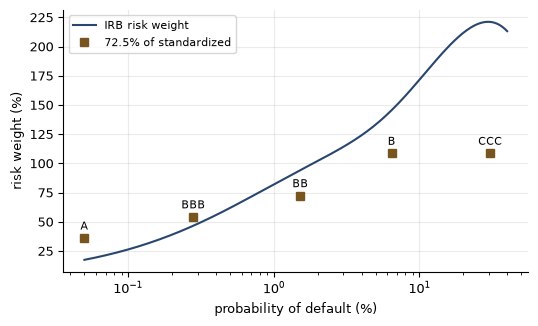

In [16]:
pds = np.logspace(log(0.0005, 10), log(0.40, 10), 200)
fig, ax = plt.subplots(figsize=(6.0, 3.4))
ax.plot(100 * pds, [100 * irb(p)["rw"] for p in pds], color=BLUE, label="IRB risk weight")
ax.plot([100 * pd for _, pd, _, _ in RATINGS], [72.5 * sa / 100 for _, _, sa, _ in RATINGS],
        "s", color=AMBER, label="72.5% of standardized")
for g, pd, sa, _ in RATINGS:
    ax.annotate(g, (100 * pd, 72.5 * sa / 100), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("probability of default (%)")
ax.set_ylabel("risk weight (%)")
ax.legend(loc="upper left", fontsize=8)
plt.show()

## 9. 1 亿美元账簿上的扣除：例 39.9

市场价格不确定性、平仓成本与模型风险所度量的内容相互重叠，因此核心法把三者相加后按一半计入；未赚取的信用利差与投资和融资成本两项调整也拆为同样的三部分，并入这一合计。其余四项全额相加。这一扣除项直接冲减核心一级资本，按假定 12% 的总资本要求，它挤占了支持 970 万美元风险加权资产的资本。

In [17]:
BOOK = 100e6
GROUPED = {"market price uncertainty": 40.0, "close-out cost": 35.0, "model risk": 60.0,
           "unearned credit spread": 10.0, "investing and funding costs": 8.0}      # basis points
FULL = {"concentrated position": 25.0, "future administrative costs": 6.0,
        "early termination": 5.0, "operational risk": 4.0}
half = 0.5 * sum(GROUPED.values())
show("grouped adjustments, counted at 50% (bp)", half, 76.5, 1e-9)
total_bp = half + sum(FULL.values())
show("total (bp)", total_bp, 116.5, 1e-9)
deduction = BOOK * total_bp / 1e4
show("deduction ($)", deduction, 1165000, 0.5)
show("risk-weighted assets displaced at 12% ($m)", deduction / 0.12 / 1e6, 9.7, 0.05)

grouped adjustments, counted at 50% (bp)                    76.5000   book       76.5000   ok
total (bp)                                                 116.5000   book      116.5000   ok
deduction ($)                                          1165000.0000   book  1165000.0000   ok
risk-weighted assets displaced at 12% ($m)                   9.7083   book        9.7000   ok


In [18]:
if BAD:
    print("有 %d 个数字与本章不符：" % len(BAD))
    for b in BAD:
        print("   ", b)
else:
    print("本章每一个经核对的数字都已复现。")

本章每一个经核对的数字都已复现。
